# L1｜收益矩阵与组合风险综合实验

本实验连接第 31–36 课：

```text
环境清单
  → Pandas 标签化行情
  → NumPy 收益矩阵
  → 按时间切分训练期和测试期
  → 训练期协方差与最小方差权重
  → 测试期固定目标权重组合收益
  → rolling 风险、净值和回撤
```

输入是 `日期 × 股票` 的复权收盘价和简单收益率；输出是训练期权重、测试期逐日组合收益、从 `1.0` 起步的净值、回撤和滚动年化波动率。目标不是寻找最赚钱组合，而是建立可复现、避免使用测试期估计权重的最小研究流程。

> **组合口径**：测试期每个收益期间都应用相同目标权重，这在数学上是固定权重 constant-mix 组合，隐含逐期再平衡且暂不计交易成本。它不是“一次买入固定股数后一直持有”。

> **数据声明**：本实验使用固定随机种子生成的 6 只虚构股票行情，不是真实证券数据。图表和指标只用于验证研究流程，不能用于判断真实市场或策略收益。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


## 1. 先看原始长表

CSV 中每行是一只虚构股票的一天记录。按日期和股票排序后展示两天数据，可直接看到同一日期对应多只股票，而不是立即把原始结构隐藏在宽表中。

In [2]:
# 读取并展示原始长表。
daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])
print("原始表形状：", daily.shape)
print("原始列：", daily.columns.tolist())
display_columns = ["date", "symbol", "sector", "adj_close", "volume"]
daily.sort_values(["date", "symbol"]).loc[:, display_columns].head(12)

原始表形状： (4536, 9)
原始列： ['date', 'symbol', 'sector', 'open', 'high', 'low', 'close', 'adj_close', 'volume']


,date,symbol,sector,adj_close,volume
0,2023-01-03,BANK_A,金融,11.7218,2822797
3024,2023-01-03,ENERGY_A,能源,6.0296,5425851
1512,2023-01-03,EV_A,新能源,27.5575,5113762
756,2023-01-03,INSURE_A,金融,41.7118,2075343
2268,2023-01-03,POWER_A,公用事业,8.0817,3733504
3780,2023-01-03,TECH_A,科技,36.2134,6241108
1,2023-01-04,BANK_A,金融,11.6934,1999548
3025,2023-01-04,ENERGY_A,能源,6.0138,2697822
1513,2023-01-04,EV_A,新能源,27.5189,4037866
757,2023-01-04,INSURE_A,金融,41.9968,5993759


### 数据契约与质量检查

研究代码至少要验证列契约、`日期 + 股票` 唯一性、缺失值和价格正值。断言负责阻止错误继续传播，带标签检查表负责让读者看到验证了什么。

In [3]:
# 把关键质量检查汇总成可见结果，再用断言阻止不合格数据继续运行。
required_columns = ["date", "symbol", "adj_close", "volume", "sector"]
quality_check = pd.Series({
    "必需列齐全": set(required_columns).issubset(daily.columns),
    "日期_股票重复行数": int(daily.duplicated(["date", "symbol"]).sum()),
    "必需字段缺失数": int(daily[required_columns].isna().sum().sum()),
    "非正复权价格数": int(daily["adj_close"].le(0).sum()),
}, name="result")

assert bool(quality_check["必需列齐全"])
assert quality_check["日期_股票重复行数"] == 0
assert quality_check["必需字段缺失数"] == 0
assert quality_check["非正复权价格数"] == 0
quality_check.to_frame()

,result
必需列齐全,True
日期_股票重复行数,0
必需字段缺失数,0
非正复权价格数,0


### 长表重排为价格矩阵

`pivot(index="date", columns="symbol", values="adj_close")` 将长表重排为：

- 行：交易日期；
- 列：股票；
- 单元格：复权收盘价。

`pivot` 遇到重复的 `date + symbol` 会报错，不会像 `pivot_table` 那样默认聚合。矩阵进入 NumPy 前，Pandas 标签是防止股票顺序错位的第一道保护。

In [4]:
# 将长表重排为“日期 × 股票”的复权收盘价矩阵。
close = (
    daily
    .pivot(index="date", columns="symbol", values="adj_close")
    .sort_index()
)

assert close.index.is_monotonic_increasing
assert close.index.is_unique and close.columns.is_unique
assert not close.isna().any().any()
print("价格矩阵 shape：", close.shape, "含义：日期 × 股票")
close.head()

价格矩阵 shape： (756, 6) 含义：日期 × 股票


symbol,BANK_A,ENERGY_A,EV_A,INSURE_A,POWER_A,TECH_A
date,,,,,,
2023-01-03,11.7218,6.0296,27.5575,41.7118,8.0817,36.2134
2023-01-04,11.6934,6.0138,27.5189,41.9968,8.1296,36.5943
2023-01-05,11.6864,6.0281,27.8166,41.7611,8.1630,36.0263
2023-01-06,11.6461,6.1016,28.7476,42.6564,8.1751,35.9828
2023-01-09,11.4919,6.0260,28.3860,41.8431,8.1925,35.7220


### 从价格矩阵计算简单收益率矩阵

`pct_change(fill_method=None)` 对每只股票列分别计算相邻交易日的简单收益率。首个价格日没有前值，因此只明确去掉第一行 `.iloc[1:]`。

本合成宽表没有中间缺失值；真实多资产数据若使用 `.dropna(axis=0, how="any")`，会删除任一股票缺失的整天，属于完整样本选择，必须记录其影响。

In [5]:
# 按股票列计算简单收益率；结果仍是“日期 × 股票”。
returns_with_first_nan = close.pct_change(fill_method=None)
returns = returns_with_first_nan.iloc[1:]

assert returns.shape == (len(close) - 1, close.shape[1])
assert returns.notna().all().all()
print("收益矩阵 shape：", returns.shape, "含义：日期 × 股票")
returns.head().style.format("{:.3%}")

收益矩阵 shape： (755, 6) 含义：日期 × 股票


symbol,BANK_A,ENERGY_A,EV_A,INSURE_A,POWER_A,TECH_A
date,,,,,,
2023-01-04 00:00:00,-0.242%,-0.262%,-0.140%,0.683%,0.593%,1.052%
2023-01-05 00:00:00,-0.060%,0.238%,1.082%,-0.561%,0.411%,-1.552%
2023-01-06 00:00:00,-0.345%,1.219%,3.347%,2.144%,0.148%,-0.121%
2023-01-09 00:00:00,-1.324%,-1.239%,-1.258%,-1.907%,0.213%,-0.725%
2023-01-10 00:00:00,-0.095%,0.418%,-0.498%,-3.167%,0.011%,0.462%


## 2. 训练期估计、测试期验证

`iloc[:split]` 和 `iloc[split:]` 沿日期方向按位置切分，不随机打乱。这里前 60% 收益观测为训练期，后 40% 为测试期；训练期结束日必须早于测试期开始日。

In [6]:
# 沿时间顺序切分，并显示两段样本的观测数和日期边界。
split = int(len(returns) * 0.6)
train = returns.iloc[:split]
test = returns.iloc[split:]
assert train.index.max() < test.index.min()

split_summary = pd.DataFrame({
    "observations": [len(train), len(test)],
    "start": [train.index.min().date(), test.index.min().date()],
    "end": [train.index.max().date(), test.index.max().date()],
}, index=["train", "test"])
split_summary

,observations,start,end
train,453,2023-01-04,2024-09-27
test,302,2024-09-30,2025-11-25


### 训练期年化协方差

`train.cov()` 默认沿日期方向，用每两只股票的训练期简单收益率计算样本协方差，得到 `(股票, 股票)` 矩阵。乘以 `252` 是日频风险常用的年化约定：

```text
年化协方差 ≈ 日协方差 × 252
```

它依赖收益分布与时间稳定性假设。乘以正数 `252` 不会改变最小方差权重，只改变目标函数和风险的单位。

In [7]:
# 计算保留股票标签的训练期年化协方差和单资产年化波动率。
annual_cov_labeled = train.cov() * 252
asset_annual_vol = pd.Series(
    np.sqrt(np.diag(annual_cov_labeled)),
    index=train.columns,
    name="annualized_vol",
)

assert annual_cov_labeled.shape == (train.shape[1], train.shape[1])
print("年化协方差 shape：", annual_cov_labeled.shape, "含义：股票 × 股票")
display(annual_cov_labeled.round(4))
asset_annual_vol.to_frame().style.format("{:.2%}")

年化协方差 shape： (6, 6) 含义：股票 × 股票


symbol,BANK_A,ENERGY_A,EV_A,INSURE_A,POWER_A,TECH_A
symbol,,,,,,
BANK_A,0.0311,0.0130,0.0205,0.0190,0.0054,0.0171
ENERGY_A,0.0130,0.0340,0.0188,0.0123,0.0051,0.0173
EV_A,0.0205,0.0188,0.0547,0.0218,0.0076,0.0259
INSURE_A,0.0190,0.0123,0.0218,0.0343,0.0069,0.0183
POWER_A,0.0054,0.0051,0.0076,0.0069,0.0197,0.0100
TECH_A,0.0171,0.0173,0.0259,0.0183,0.0100,0.0518


,annualized_vol
symbol,
BANK_A,17.64%
ENERGY_A,18.44%
EV_A,23.40%
INSURE_A,18.51%
POWER_A,14.03%
TECH_A,22.77%


### 先用二资产小例子理解 `w @ Σ @ w`

权重 `w` 的 shape 为 `(N,)`，协方差 `Σ` 的 shape 为 `(N, N)`：

```text
(N,) @ (N, N) @ (N,) → 标量组合方差
```

组合波动率是方差的平方根。下面两资产无相关性，第二项波动更低，因此最小方差权重会更多配置第二项。

In [8]:
# 用确定性二资产协方差核对组合方差和波动率。
demo_cov = np.array([
    [0.04, 0.00],
    [0.00, 0.01],
])
demo_weights = pd.DataFrame(
    {
        "equal": [0.50, 0.50],
        "minvar": [0.20, 0.80],
    },
    index=["资产A", "资产B"],
)
demo_risk = pd.DataFrame({
    "variance": {
        column: float(demo_weights[column].to_numpy() @ demo_cov @ demo_weights[column].to_numpy())
        for column in demo_weights
    }
})
demo_risk["volatility"] = np.sqrt(demo_risk["variance"])

assert np.isclose(demo_risk.loc["equal", "variance"], 0.0125)
assert np.isclose(demo_risk.loc["minvar", "variance"], 0.0080)
demo_risk.style.format({"variance": "{:.4f}", "volatility": "{:.2%}"})

,variance,volatility
equal,0.0125,11.18%
minvar,0.0080,8.94%


### 用 SLSQP 求训练期 long-only 最小方差权重

优化目标是年化组合方差 `w @ Σ @ w`。约束含义：

- `bounds=[(0, 1)] * N`：每只股票权重在 0 到 100% 之间，禁止做空；
- `sum(w) - 1 = 0`：权重总和为 1，资金全部投入；
- `x0=equal_weights`：以等权组合为数值搜索起点；
- `method="SLSQP"`：处理边界和等式约束的数值优化方法。

该问题没有预期收益目标，因此“最小方差”不等于“最高收益”。

In [9]:
# 仅使用训练期协方差求解最小方差权重。
from scipy.optimize import minimize

annual_cov = annual_cov_labeled.to_numpy(dtype=np.float64)
n_assets = train.shape[1]
equal_weights = np.full(n_assets, 1 / n_assets)

def portfolio_variance(weight_vector, covariance):
    return float(weight_vector @ covariance @ weight_vector)

result = minimize(
    fun=portfolio_variance,
    x0=equal_weights,
    args=(annual_cov,),
    method="SLSQP",
    bounds=[(0.0, 1.0)] * n_assets,
    constraints={"type": "eq", "fun": lambda w: w.sum() - 1},
)
assert result.success, result.message
minvar_weights = result.x
assert np.isclose(minvar_weights.sum(), 1)
assert (minvar_weights >= -1e-10).all()

weight_matrix = pd.DataFrame(
    {
        "等权": equal_weights,
        "训练期最小方差": minvar_weights,
    },
    index=train.columns,
)
weight_matrix.index.name = "symbol"

print("优化状态：", result.message)
print("迭代次数：", result.nit)
weight_matrix.style.format("{:.2%}")

优化状态： Optimization terminated successfully
迭代次数： 9


,等权,训练期最小方差
symbol,,
BANK_A,16.67%,16.87%
ENERGY_A,16.67%,19.90%
EV_A,16.67%,0.00%
INSURE_A,16.67%,11.07%
POWER_A,16.67%,52.16%
TECH_A,16.67%,0.00%


### 检查训练期目标风险

最小方差权重应在训练期协方差口径下不高于等权组合风险。这个断言验证优化目标，但不保证测试期收益、波动或回撤一定更好。

In [10]:
# 比较两个组合在训练期协方差下的方差和年化波动率。
training_risk = pd.DataFrame({
    "variance": {
        "等权": portfolio_variance(equal_weights, annual_cov),
        "训练期最小方差": portfolio_variance(minvar_weights, annual_cov),
    }
})
training_risk["annual_vol"] = np.sqrt(training_risk["variance"])

assert training_risk.loc["训练期最小方差", "variance"] <= training_risk.loc["等权", "variance"] + 1e-12
training_risk.style.format({"variance": "{:.6f}", "annual_vol": "{:.2%}"})

,variance,annual_vol
等权,0.018429,13.58%
训练期最小方差,0.012934,11.37%


权重只使用训练期数据估计，测试期不重新估计。随后每个测试期收益都乘同一组目标权重，数学上隐含每期再平衡回目标比例且成本为 0。

这与“一次买入后固定股数”不同：买入持有组合的权重会随各资产价格涨跌而漂移。真正滚动研究还应在每个再估计日只使用当时可得窗口，并明确再平衡频率和成本。

## 3. 测试期组合收益：先保留标签，再用 NumPy 校验

`test` 的 shape 是 `(T, N)`：日期 × 股票；`weight_matrix` 的 shape 是 `(N, K)`：股票 × 组合。

```text
(T, N) @ (N, K) → (T, K)
```

`DataFrame.dot` 会按股票标签检查和对齐；NumPy `@` 只按位置运算。因此先用 Pandas 得到安全结果，再显式断言列顺序，并用 NumPy 独立校验。

In [11]:
# 用标签安全的矩阵乘法计算两个组合的测试期逐日收益。
assert test.columns.equals(weight_matrix.index)
portfolio_returns = test.dot(weight_matrix)

test_array = test.to_numpy(dtype=np.float64)
weight_array = weight_matrix.to_numpy(dtype=np.float64)
portfolio_returns_np = test_array @ weight_array
np.testing.assert_allclose(
    portfolio_returns.to_numpy(),
    portfolio_returns_np,
)

print(
    "shape：",
    "test", test.shape,
    "@ weights", weight_matrix.shape,
    "=", portfolio_returns.shape,
)
portfolio_returns.head().style.format("{:.3%}")

shape： test (302, 6) @ weights (6, 2) = (302, 2)


,等权,训练期最小方差
date,,
2024-09-30 00:00:00,-0.901%,-0.881%
2024-10-01 00:00:00,1.083%,1.145%
2024-10-02 00:00:00,0.509%,0.697%
2024-10-03 00:00:00,0.799%,0.887%
2024-10-04 00:00:00,0.392%,0.780%


### 用首个测试日核对每只股票的收益贡献

逐元素乘法保留每只股票的贡献；沿股票行求和后，等于矩阵乘法得到的当日组合收益。贡献表同时展示资产收益、权重和两个组合的贡献，避免只看到最终标量。

In [12]:
# 拆解首个测试日的逐股票贡献，并用合计校验组合收益。
first_test_date = test.index[0]
first_day_return = test.loc[first_test_date]
first_day_contribution = pd.DataFrame({
    "asset_return": first_day_return,
    "equal_weight": weight_matrix["等权"],
    "equal_contribution": first_day_return * weight_matrix["等权"],
    "minvar_weight": weight_matrix["训练期最小方差"],
    "minvar_contribution": first_day_return * weight_matrix["训练期最小方差"],
})

np.testing.assert_allclose(
    [
        first_day_contribution["equal_contribution"].sum(),
        first_day_contribution["minvar_contribution"].sum(),
    ],
    portfolio_returns.loc[first_test_date],
)
print("首个测试日：", first_test_date.date())
first_day_contribution.style.format("{:.3%}")

首个测试日： 2024-09-30


,asset_return,equal_weight,equal_contribution,minvar_weight,minvar_contribution
symbol,,,,,
BANK_A,-2.460%,16.667%,-0.410%,16.872%,-0.415%
ENERGY_A,-1.405%,16.667%,-0.234%,19.897%,-0.279%
EV_A,0.506%,16.667%,0.084%,0.000%,0.000%
INSURE_A,-1.206%,16.667%,-0.201%,11.071%,-0.134%
POWER_A,-0.102%,16.667%,-0.017%,52.160%,-0.053%
TECH_A,-0.741%,16.667%,-0.124%,0.000%,-0.000%


## 4. 从 `1.0` 起步构造净值与回撤

`cumprod(axis=0)` 沿日期方向对每个组合分别复合收益。测试期首个收益发生前的资本是 `1.0`，因此先在训练期最后日期加入净值起点，再计算历史峰值和回撤：

```text
净值 = (1 + 每期收益) 的累计乘积
历史峰值 = 截至当前的累计最大净值
回撤 = 当前净值 / 历史峰值 - 1
```

In [13]:
# 在第一个测试收益发生前加入 1.0 起点，再计算净值、峰值和回撤。
initial_nav = pd.DataFrame(
    [np.ones(portfolio_returns.shape[1])],
    index=pd.DatetimeIndex(
        [train.index[-1]],
        name=portfolio_returns.index.name,
    ),
    columns=portfolio_returns.columns,
)
nav = pd.concat([
    initial_nav,
    (1 + portfolio_returns).cumprod(axis=0),
])
running_peak = nav.cummax(axis=0)
drawdown = nav / running_peak - 1

assert np.allclose(nav.iloc[0], 1.0)
assert (drawdown <= 1e-12).all().all()
drawdown_diagnostics = pd.DataFrame({
    "max_drawdown": drawdown.min(),
    "worst_date": drawdown.idxmin(),
})

display(nav.head(3).round(6))
drawdown_diagnostics.style.format({"max_drawdown": "{:.2%}"})

,等权,训练期最小方差
date,,
2024-09-27,1.000000,1.000000
2024-09-30,0.990987,0.991188
2024-10-01,1.001715,1.002536


,max_drawdown,worst_date
等权,-5.97%,2024-12-05 00:00:00
训练期最小方差,-7.22%,2025-02-04 00:00:00


### 60 观测滚动年化波动率

`rolling(window=60, min_periods=60)` 对每个组合列分别取最近 60 个收益观测；它不是 60 个自然日。`std(ddof=1)` 计算窗口样本标准差，乘 `sqrt(252)` 按日频惯例年化。

它是历史实现波动率估计，不是未来风险保证。

In [14]:
# 对每个组合分别计算 60 观测滚动年化波动率。
rolling_vol = (
    portfolio_returns
    .rolling(window=60, min_periods=60)
    .std(ddof=1)
    * np.sqrt(252)
)

assert rolling_vol.iloc[:59].isna().all().all()
print("首个完整 60 观测窗口日期：", rolling_vol.dropna().index[0].date())
rolling_vol.dropna().head().style.format("{:.2%}")

首个完整 60 观测窗口日期： 2024-12-20


,等权,训练期最小方差
date,,
2024-12-20 00:00:00,13.07%,11.76%
2024-12-23 00:00:00,12.94%,11.71%
2024-12-24 00:00:00,12.81%,11.52%
2024-12-25 00:00:00,12.85%,11.59%
2024-12-26 00:00:00,12.78%,11.45%


### 测试期指标汇总

- 几何年化收益：用测试期末净值和测试收益观测数按 252 期年化；
- 年化样本波动率：测试期日收益样本标准差乘 `sqrt(252)`；
- 最大回撤：包含 `1.0` 起点的回撤序列最小值。

三者描述不同性质，最小方差组合不保证收益最高，也不保证最大回撤最浅。

In [15]:
# 汇总测试期几何年化收益、年化样本波动率和最大回撤。
summary = pd.DataFrame({
    "annualized_geometric_return": nav.iloc[-1] ** (252 / len(portfolio_returns)) - 1,
    "annualized_sample_vol": portfolio_returns.std(axis=0, ddof=1) * np.sqrt(252),
    "max_drawdown": drawdown.min(),
})

display(summary.style.format("{:.2%}"))
print("解读：请比较波动率、收益和最大回撤；三项排序不必一致。")

,annualized_geometric_return,annualized_sample_vol,max_drawdown
等权,18.67%,13.06%,-5.97%
训练期最小方差,10.34%,11.30%,-7.22%


解读：请比较波动率、收益和最大回撤；三项排序不必一致。


## 5. 矢量化结果与显式循环一致

性能比较前必须先验证正确性。循环函数显式检查输入 shape，避免 `zip` 在权重长度错误时静默截断：

- 收益矩阵：`(T, N)`；
- 单组合权重：`(N,)`；
- 输出：`(T,)`。

In [16]:
# 用显式循环复算最小方差组合，并展示前 5 日逐项一致。
def loop_portfolio(matrix, weight_vector):
    matrix = np.asarray(matrix)
    weight_vector = np.asarray(weight_vector)
    assert matrix.ndim == 2
    assert weight_vector.shape == (matrix.shape[1],)

    output = np.empty(matrix.shape[0], dtype=np.float64)
    for row_index, row in enumerate(matrix):
        total = 0.0
        for column_index, value in enumerate(row):
            total += value * weight_vector[column_index]
        output[row_index] = total
    return output

loop_result = loop_portfolio(test_array, minvar_weights)
vector_result = test_array @ minvar_weights
np.testing.assert_allclose(loop_result, vector_result)

print("校验通过：循环与矩阵乘法结果一致。")
pd.DataFrame({
    "loop": loop_result[:5],
    "matrix_multiplication": vector_result[:5],
}, index=test.index[:5]).round(8)

校验通过：循环与矩阵乘法结果一致。


,loop,matrix_multiplication
date,,
2024-09-30,-0.008812,-0.008812
2024-10-01,0.011448,0.011448
2024-10-02,0.006971,0.006971
2024-10-03,0.008865,0.008865
2024-10-04,0.007803,0.007803


### 只在结果一致后比较性能

`np.tile(test_array, (300, 1))` 只沿日期方向重复同一测试矩阵以放大计时差异；它没有产生新市场信息，不能当作扩充回测样本。循环和矩阵乘法使用相同的 `number` 与 `repeat` 设置，倍数只代表本机本次运行。

In [17]:
# 重复同一矩阵做本机性能实验，不把重复数据解释成新样本。
large = np.tile(test_array, (300, 1))
repeat_count = 3
print("性能测试 shape：", test_array.shape, "→", large.shape)

loop_time = min(timeit.repeat(
    lambda: loop_portfolio(large, minvar_weights),
    number=1,
    repeat=repeat_count,
))
vector_time = min(timeit.repeat(
    lambda: large @ minvar_weights,
    number=1,
    repeat=repeat_count,
))
print(f"循环：{loop_time:.4f}s")
print(f"矩阵乘法：{vector_time:.4f}s")
print(f"本机加速倍数：{loop_time / vector_time:.1f}x")

性能测试 shape： (302, 6) → (90600, 6)


循环：0.0670s
矩阵乘法：0.0001s
本机加速倍数：603.8x


## 6. 图形诊断

三张图分别回答：测试期资本如何复合、组合曾从历史峰值下跌多少、最近 60 个收益观测的历史波动率是多少。净值高低不能代替回撤或波动率诊断。

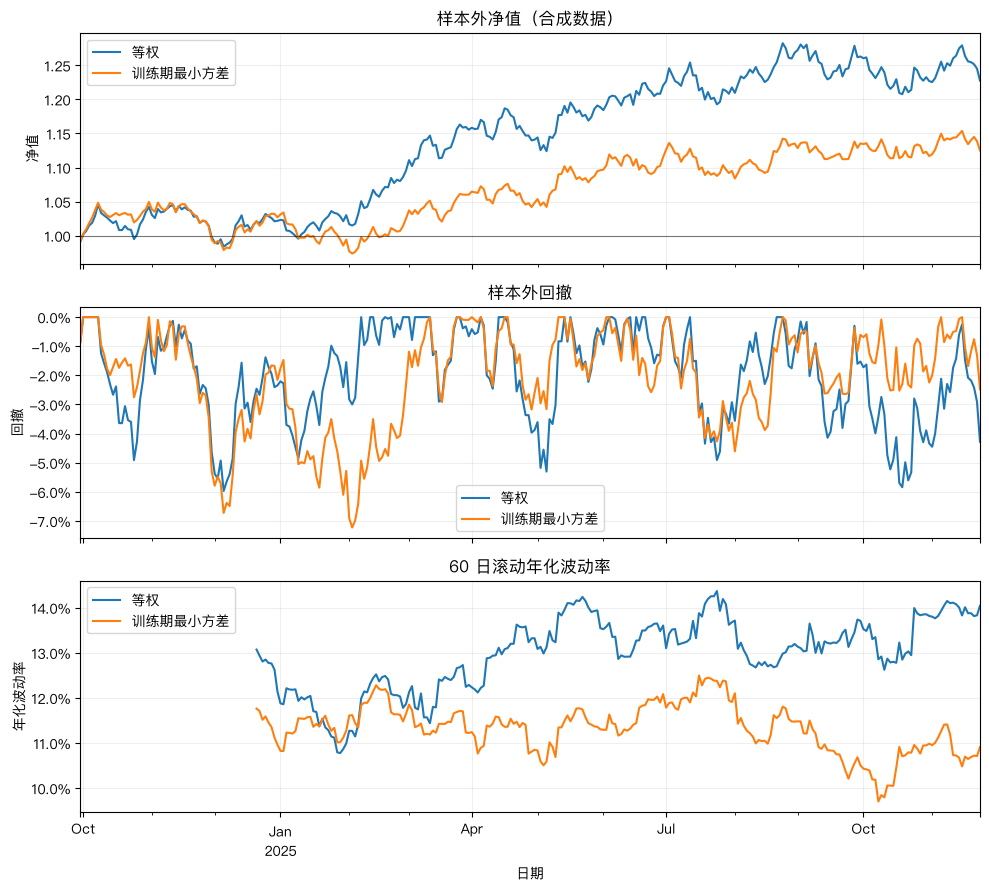

In [18]:
# 绘制带明确单位的测试期净值、回撤和滚动波动率。
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
nav.plot(ax=axes[0], title="样本外净值（合成数据）")
drawdown.plot(ax=axes[1], title="样本外回撤")
rolling_vol.plot(ax=axes[2], title="60 日滚动年化波动率")
axes[0].set_ylabel("净值")
axes[0].axhline(1.0, color="black", linewidth=0.8, alpha=0.5)
axes[1].set_ylabel("回撤")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[2].set_ylabel("年化波动率")
axes[2].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[2].set_xlabel("日期")
for axis in axes:
    axis.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "L1_portfolio_risk.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

### 如何解读本次确定性合成样本

先看汇总表确认哪个组合的测试期波动率较低，再分别检查年化收益和最大回撤。训练期最小方差只优化训练期协方差口径；即使测试期波动较低，也不推出测试期收益更高或最大回撤更小。

## 7. 验收与方法边界

- 输入价格以日期和证券标签唯一对齐。
- 收益矩阵为 `日期 × 股票`，权重为 `股票`。
- `to_numpy()` 会移除股票标签，数值运算前必须断言列顺序。
- 权重只在训练期估计，测试期不使用未来样本重新估计。
- 长仓最小方差权重有总和与上下界约束。
- 测试期每期使用同一目标权重，隐含逐期再平衡和零交易成本；它不是固定股数买入持有。
- 若一次买入后不再平衡，应计算各资产财富腿和随价格漂移的权重，不能每天直接使用初始权重做 `R @ w`。
- 日频协方差乘 252 和波动率乘 `sqrt(252)` 是年化约定，不是稳定分布保证。
- 训练期样本协方差存在估计误差、共线性和结构漂移；最小方差权重可能集中且不稳定。
- 完整行缺失删除会改变共同样本；真实数据必须记录上市、停牌和缺失处理。
- 循环和矩阵乘法结果一致，性能倍数由本机实测。
- 尚未加入手续费、滑点、停牌、涨跌停、可成交价格、复权事件和权重漂移，因此本实验不是完整回测。
- 测试期只是同一确定性合成过程的时间后段，不能代表真实市场的实盘外推。

## 8. 可复用结论与练习

可复用研究顺序：

```text
原始长表 → 数据契约 → 日期 × 股票价格
          → 简单收益率 → 时间切分
          → 训练期协方差 → 受约束权重
          → 标签安全的样本外组合收益
          → 1.0 起点净值 → 峰值/回撤/滚动风险
```

练习：

1. 打乱 `weight_matrix` 的股票索引，比较 Pandas `dot` 与未检查列顺序的 NumPy `@`。
2. 把训练比例改为 50% 和 70%，记录权重、训练风险和测试风险如何变化。
3. 将固定目标权重组合改为一次买入后的固定股数持有，比较权重漂移和净值。
4. 加入每次再平衡的双边成本，并比较日度、月度再平衡。
5. 给单只股票引入若干缺失日，分别测试完整行删除、停牌零收益假设和可投资股票池变化；说明每种处理的业务含义。